# E-Commerce Product Rating Prediction based on Price and Reviews


Regression

Mihera Gaikee

B2-B1-13

In [ ]:
!pip install statsmodels -q

import requests, json, time, re
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

##Scraping Walmart pages using API

In [ ]:
API_KEY = "288a5967683c6063406205ab0f9ca866"
BASE = "https://www.walmart.com/shop/deals/flash-deals-shopall"
NUM_PAGES = 10  # increase for more items

def get_items(page):
    target = f"{BASE}?page={page}"
    r = requests.get(
        "https://api.scraperapi.com/",
        params={"api_key": API_KEY, "url": target},   # plain works; no render/premium needed
        timeout=90,
    )
    soup = BeautifulSoup(r.text, "html.parser")
    tag = soup.find("script", id="__NEXT_DATA__")
    if tag is None:
        print(f"page {page}: no data (status {r.status_code}, title: {soup.title.text if soup.title else None})")
        return []
    data = json.loads(tag.string)
    stacks = data["props"]["pageProps"]["initialData"]["searchResult"]["itemStacks"]
    items = []
    for stack in stacks:
        items.extend(stack.get("items", []))
    return items

all_items = []
for page in range(1, NUM_PAGES + 1):
    page_items = get_items(page)
    print(f"page {page}: {len(page_items)} items")
    if not page_items:
        break
    all_items.extend(page_items)
    time.sleep(2)

print("Raw items collected:", len(all_items))

page 1: 71 items
page 2: 71 items
page 3: 71 items
page 4: 71 items
page 5: 71 items
page 6: 71 items
page 7: 71 items
page 8: 71 items
page 9: 71 items
page 10: 71 items
Raw items collected: 710


In [ ]:
#confirm the field names
for it in all_items:
    if it.get("name"):
        print({k: it.get(k) for k in ["usItemId", "name", "averageRating", "numberOfReviews", "priceInfo"]})
        break

{'usItemId': '19693460687', 'name': 'MOOSOO Cordless Stick Vacuum Cleaner, 40KPA 50mins 2600mAh Lightweight Upright for Carpet Hard Floor Pet Hair, XL-618A', 'averageRating': 3.8, 'numberOfReviews': 14618, 'priceInfo': {'itemPrice': '', 'linePrice': '$68.99', 'linePriceDisplay': 'Now $68.99', 'savings': 'SAVE $101.00', 'savingsAmt': 101, 'wasPrice': '$169.99', 'unitPrice': '', 'shipPrice': '', 'minPrice': 0, 'minPriceForVariant': '', 'priceRangeString': '', 'subscriptionPrice': '', 'subscriptionString': '', 'priceDisplayCondition': '', 'finalCostByWeight': False, 'submapType': '', 'eaPricingText': '', 'eaPricingPreText': '', 'memberPriceString': '', 'subscriptionDualPrice': None, 'subscriptionPercentage': None, 'isB2BPrice': False, 'priceDisplayType': 'UNKNOWN', 'taxInfo': None}}


In [ ]:
sample = next(it for it in all_items if it.get("name"))
print(list(sample.keys()))

['__typename', 'buyBoxSuppression', 'similarItems', 'id', 'usItemId', 'fitmentLabel', 'name', 'checkStoreAvailabilityATC', 'seeShippingEligibility', 'brand', 'type', 'shortDescription', 'averageWeight', 'weightIncrement', 'topResult', 'additionalOfferCount', 'availabilityInNearbyStore', 'availabilityType', 'startDate', 'itemBeacon', 'catalogProductType', 'collectibles', 'gradingTypeCode', 'conditionPriceRange', 'imageInfo', 'aspectInfo', 'plItem', 'canonicalUrl', 'conditionV2', 'externalInfo', 'itemType', 'category', 'returnPolicy', 'badges', 'buyNowEligible', 'classType', 'averageRating', 'numberOfReviews', 'departmentName', 'esrb', 'mediaRating', 'salesUnitType', 'sellerId', 'sellerName', 'sellerType', 'hasSellerBadge', 'isEarlyAccessItem', 'preEarlyAccessEvent', 'earlyAccessEvent', 'blitzItem', 'annualEvent', 'annualEventV2', 'availabilityStatusV2', 'groupMetaData', 'addOnServices', 'productLocation', 'fulfillmentSpeed', 'offerId', 'preOrder', 'pac', 'droneAttributes', 'fulfillmentS

In [ ]:
for k in ["departmentName", "category", "sellerType", "sellerName", "fulfillmentType",
          "fulfillmentSpeed", "isSponsoredFlag", "badges", "manufacturerName", "brand"]:
    print(k, "->", repr(sample.get(k))[:200])

departmentName -> 'Home'
category -> {'categoryPathId': '0:4044:90548:4047:5775266', 'path': None}
sellerType -> None
sellerName -> 'MOOSOO DIRECT'
fulfillmentType -> 'FC'
fulfillmentSpeed -> None
isSponsoredFlag -> True
badges -> {'flags': [{'__typename': 'BaseBadge', 'key': 'BESTSELLER', 'text': 'Best seller', 'type': 'LABEL', 'id': 'L1600', 'styleId': 'TERTIARY_BLUE_BOLD'}], 'tags': [{'__typename': 'BaseBadge', 'key': 'SAVE_
manufacturerName -> None
brand -> None


## Building the DF



In [ ]:
def parse_money(s):
    try:
        m = re.search(r"\d[\d,]*\.?\d*", str(s))
        return float(m.group().replace(",", "")) if m else np.nan
    except Exception:
        return np.nan

def get_price(it):
    pi = it.get("priceInfo") or {}
    for k in ["linePrice", "itemPrice", "linePriceDisplay", "minPriceForVariant", "priceRangeString"]:
        v = parse_money(pi.get(k))
        if not np.isnan(v):
            return v
    return np.nan

def cat_levels(it):
    c = it.get("category") or {}
    parts = str(c.get("categoryPathId") or "").split(":")
    l1 = parts[1] if len(parts) > 1 else "unknown"
    l2 = parts[2] if len(parts) > 2 else "unknown"
    return l1, l2

def badge_info(it):
    b = it.get("badges") or {}
    flags = b.get("flags") or []
    tags = b.get("tags") or []
    keys = [f.get("key", "") for f in flags]
    return int("BESTSELLER" in keys), len(flags), len(tags)

rows = []
for it in all_items:
    name = it.get("name")
    if name is None:
        continue
    pi = it.get("priceInfo") or {}
    l1, l2 = cat_levels(it)
    best, n_flags, n_tags = badge_info(it)
    rows.append({
        "product_id": it.get("usItemId") or it.get("id"),
        "name": name,
        "price": get_price(it),
        "was_price": parse_money(pi.get("wasPrice")),
        "savings": pi.get("savingsAmt"),
        "rating": it.get("averageRating"),
        "num_reviews": it.get("numberOfReviews"),
        "dept": it.get("departmentName"),
        "cat_l1": l1,
        "cat_l2": l2,
        "seller": it.get("sellerName"),
        "fulfillment": it.get("fulfillmentType"),
        "short_desc": it.get("shortDescription"),
        "sponsored": it.get("isSponsoredFlag"),
        "bestseller": best,
        "n_flags": n_flags,
        "n_tags": n_tags,
    })

d = pd.DataFrame(rows)
for c in ["price", "was_price", "savings", "rating", "num_reviews"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")

d["num_reviews"] = d["num_reviews"].fillna(0)
d = d.dropna(subset=["price", "rating"])
d = d[d["price"] > 0].drop_duplicates(subset="product_id").reset_index(drop=True)

# numeric features
d["log_price"] = np.log1p(d["price"])
d["log_reviews"] = np.log1p(d["num_reviews"])
d["discount_pct"] = ((d["was_price"] - d["price"]) / d["was_price"]).clip(0, 1).fillna(0)
d["savings"] = d["savings"].fillna(0)
d["name_len"] = d["name"].str.len()
d["name_words"] = d["name"].str.split().str.len()
d["desc_len"] = d["short_desc"].fillna("").astype(str).str.len()
d["has_clearance"] = d["name"].str.contains("clearance", case=False).astype(int)
d["is_walmart_seller"] = d["seller"].fillna("").astype(str).str.contains("walmart", case=False).astype(int)
d["seller_freq"] = d.groupby("seller")["product_id"].transform("count").fillna(1)
d["sponsored"] = d["sponsored"].fillna(False).astype(int)

# categorical features
for c in ["dept", "cat_l1", "cat_l2", "fulfillment"]:
    d[c] = d[c].fillna("unknown").astype(str)

# simple dataframe used by the cleaning / EDA / regression cells below
df = d[["product_id", "name", "price", "rating", "num_reviews"]].rename(columns={"name": "product_name"}).copy()

print(d.shape)
print(d["dept"].value_counts().head(10))
print(d["bestseller"].mean(), d["cat_l1"].nunique(), d["cat_l2"].nunique())

(608, 26)
dept
Home                   190
Clothing               131
Patio & Garden          43
Home Improvement        32
Electronics             27
Sports & Outdoors       26
Toys                    21
Baby                    18
Pets                    18
Health and Medicine     15
Name: count, dtype: int64
0.6546052631578947 28 135


## Cleaning

In [ ]:
for col in ["price", "rating", "num_reviews"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dtypes

,0
product_id,object
product_name,object
price,float64
rating,float64
num_reviews,float64


## Handle missing values


In [ ]:
print(df.isnull().sum())

df_clean = df.copy()
df_clean["num_reviews"] = df_clean["num_reviews"].fillna(0)      # no reviews listed -> 0
df_clean = df_clean.dropna(subset=["price", "rating"])           # need both for the model
df_clean = df_clean[df_clean["price"] > 0]

print("\nAfter handling missing values:", df_clean.shape)
print(df_clean.isnull().sum())

product_id      0
product_name    0
price           0
rating          0
num_reviews     0
dtype: int64

After handling missing values: (608, 5)
product_id      0
product_name    0
price           0
rating          0
num_reviews     0
dtype: int64


## Handle duplicates

In [ ]:
print("Duplicate product_ids:", df_clean.duplicated(subset="product_id").sum())
df_clean = df_clean.drop_duplicates(subset="product_id").reset_index(drop=True)
print("Shape after removing duplicates:", df_clean.shape)
df_clean.head(10)

Duplicate product_ids: 0
Shape after removing duplicates: (608, 5)


,product_id,product_name,price,rating,num_reviews
0,19693460687,"MOOSOO Cordless Stick Vacuum Cleaner, 40KPA 50...",68.99,3.8,14618.0
1,17810565859,PALIFEUR Bath Towels Premium Checkered Bath To...,0.21,2.7,143.0
2,15539208397,"SERWALL Oversized Outdoor Rocking Chair, All-W...",88.99,4.5,2075.0
3,20126053272,"Sasttie Chenille Bathroom Rugs 17x24, Quick Dr...",6.29,4.5,213.0
4,20678611207,Clearance! Christmas Pearl Art Kits for Adults...,4.67,4.2,465.0
5,20233074862,VNJQPG Women's Fall Colorful Pumpkin Graphic C...,7.99,4.7,31.0
6,3353912489,LONKITO Mens Sweatpants with Pockets Outdoor R...,9.97,3.9,1573.0
7,20424207259,Women's 3/4 Sleeve Fall Halloween Shirt Pumpki...,6.99,4.6,51.0
8,1281794492,"MXZ Gaming PC Computer AMD Ryzen 5 5500, RTX 3...",979.60,4.3,173.0
9,19398205938,REDESS Wide Leg Pants for Women Palazzo Drawst...,9.99,4.0,25.0


## EDA



In [ ]:
df_clean[["price", "rating", "num_reviews"]].describe()

,price,rating,num_reviews
count,608.000000,608.000000,608.000000
mean,92.291595,4.360526,1511.585526
std,191.343834,0.331917,3311.693460
min,0.210000,2.700000,1.000000
25%,16.990000,4.200000,95.750000
50%,30.580000,4.400000,372.000000
75%,81.187500,4.600000,1213.500000
max,2503.000000,5.000000,30107.000000


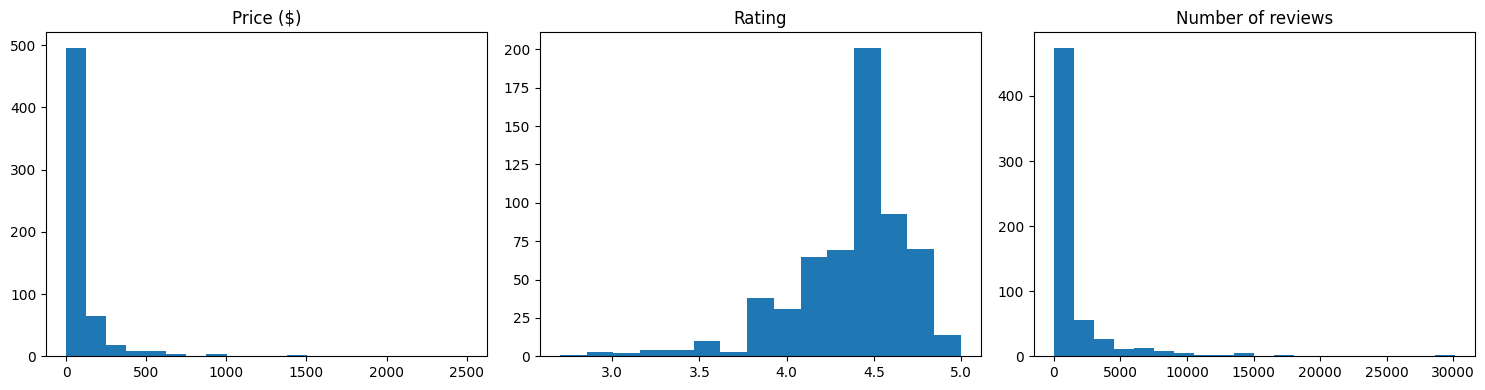

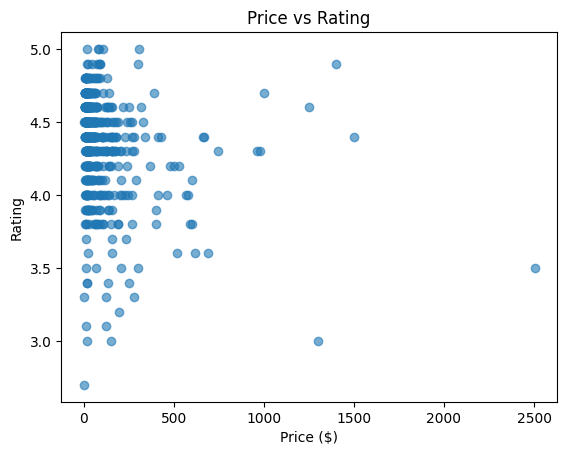

,price,rating,num_reviews
price,1.000000,-0.212296,-0.091929
rating,-0.212296,1.000000,0.009458
num_reviews,-0.091929,0.009458,1.000000


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df_clean["price"], bins=20);       ax[0].set_title("Price ($)")
ax[1].hist(df_clean["rating"], bins=15);      ax[1].set_title("Rating")
ax[2].hist(df_clean["num_reviews"], bins=20); ax[2].set_title("Number of reviews")
plt.tight_layout(); plt.show()

plt.scatter(df_clean["price"], df_clean["rating"], alpha=0.6)
plt.xlabel("Price ($)"); plt.ylabel("Rating"); plt.title("Price vs Rating")
plt.show()

df_clean[["price", "rating", "num_reviews"]].corr()

## Confidence Interval and One-Sample t-test

In [ ]:
import numpy as np
from scipy import stats

# Get product ratings
ratings = df_clean["rating"]

# Calculate sample mean and standard error
mean_rating = ratings.mean()
n = len(ratings)
se = stats.sem(ratings)

# 95% Confidence Interval
ci = stats.t.interval(
    0.95, df=n-1, loc=mean_rating, scale=se
)

print("Mean Rating:", round(mean_rating, 3))
print("95% Confidence Interval:", ci)

# One-sample t-test
# H0: Population mean rating = 4.0
# H1: Population mean rating != 4.0
t_stat, p_value = stats.ttest_1samp(ratings, popmean=4.0)

print("T-statistic:", round(t_stat, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject H0: Mean rating is significantly different from 4.0.")
else:
    print("Fail to reject H0: No significant difference from 4.0.")

Mean Rating: 4.361
95% Confidence Interval: (np.float64(4.334090483674948), np.float64(4.386962147904))
T-statistic: 26.783
P-value: 0.0
Reject H0: Mean rating is significantly different from 4.0.


##Hypothesis test for correlation
H0: true correlation between price and rating = 0  vs  H1: correlation != 0

In [ ]:
x = df_clean["price"]
y = df_clean["rating"]

r, p = stats.pearsonr(x, y)
print("Pearson r:", r)
print("P-value:", p)

rho, p_s = stats.spearmanr(x, y)       # robust to skewed prices
print("Spearman rho:", rho, " p-value:", p_s)

if p < 0.05:
    print("Reject H0: significant linear correlation between price and rating.")
else:
    print("Fail to reject H0: no significant linear correlation found.")

Pearson r: -0.21229568994087955
P-value: 1.2619168062891058e-07
Spearman rho: -0.2526054834606575  p-value: 2.6395205029050204e-10
Reject H0: significant linear correlation between price and rating.


##Simple Linear Regression: rating = intercept + slope x price

In [ ]:
result = stats.linregress(x, y)

print("Slope:", result.slope)
print("Intercept:", result.intercept)
print("R-squared:", result.rvalue ** 2)
print("P-value (H0: slope = 0):", result.pvalue)
print("Std error of slope:", result.stderr)

n = len(x)
df_resid = n - 2
t_crit = stats.t.ppf(0.975, df_resid)
margin = t_crit * result.stderr
print("\n95% CI for slope:", (result.slope - margin, result.slope + margin))

Slope: -0.00036826171066372865
Intercept: 4.394513776589425
R-squared: 0.045069459967474045
P-value (H0: slope = 0): 1.261916806289136e-07
Std error of slope: 6.885967497559633e-05

95% CI for slope: (np.float64(-0.0005034942844044091), np.float64(-0.00023302913692304817))


### Prediction with 95% prediction interval

In [ ]:
new_price = 30

pred = result.intercept + result.slope * new_price

fitted = result.intercept + result.slope * x
resid = y - fitted
s = np.sqrt((resid ** 2).sum() / df_resid)          # standard error of the estimate
Sxx = ((x - x.mean()) ** 2).sum()

pred_se = s * np.sqrt(1 + 1/n + (new_price - x.mean()) ** 2 / Sxx)
pi_margin = t_crit * pred_se

print(f"Predicted rating at ${new_price}: {pred:.3f}")
print("95% Prediction interval:", (pred - pi_margin, pred + pi_margin))

conf_se = s * np.sqrt(1/n + (new_price - x.mean()) ** 2 / Sxx)
print("95% Confidence interval for mean rating:", (pred - t_crit*conf_se, pred + t_crit*conf_se))

Predicted rating at $30: 4.383
95% Prediction interval: (np.float64(3.745371667741327), np.float64(5.021560182797698))
95% Confidence interval for mean rating: (np.float64(4.356273587499954), np.float64(4.410658263039071))


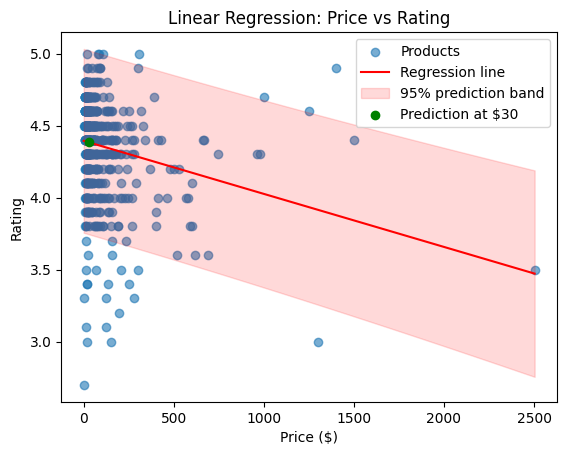

In [ ]:
xs = np.linspace(x.min(), x.max(), 100)
ys = result.intercept + result.slope * xs
band = t_crit * s * np.sqrt(1 + 1/n + (xs - x.mean()) ** 2 / Sxx)

plt.scatter(x, y, alpha=0.6, label="Products")
plt.plot(xs, ys, color="red", label="Regression line")
plt.fill_between(xs, ys - band, ys + band, color="red", alpha=0.15, label="95% prediction band")
plt.scatter([new_price], [pred], color="green", zorder=5, label=f"Prediction at ${new_price}")
plt.xlabel("Price ($)"); plt.ylabel("Rating"); plt.legend()
plt.title("Linear Regression: Price vs Rating"); plt.show()

## Multiple Regression: rating ~ price + number of reviews

In [ ]:
X = df_clean[["price", "num_reviews"]]
X = sm.add_constant(X)
model = sm.OLS(df_clean["rating"], X).fit()

print(model.summary())
print("\n95% CIs for coefficients:")
print(model.conf_int(alpha=0.05))

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     14.31
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           8.46e-07
Time:                        05:52:49   Log-Likelihood:                -177.62
No. Observations:                 608   AIC:                             361.2
Df Residuals:                     605   BIC:                             374.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           4.3962      0.016    273.689      

In [ ]:
# Prediction + 95% prediction interval for a new product
new = pd.DataFrame({"const": [1], "price": [30], "num_reviews": [100]})
pred_res = model.get_prediction(new).summary_frame(alpha=0.05)
print(pred_res[["mean", "obs_ci_lower", "obs_ci_upper"]])

       mean  obs_ci_lower  obs_ci_upper
0  4.385002      3.746302      5.023701


##Model comparison and selection


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestRegressor,
                              ExtraTreesRegressor, AdaBoostRegressor,
                              HistGradientBoostingRegressor)
from sklearn.model_selection import cross_val_score, RepeatedKFold

num_cols = ["log_price", "log_reviews", "discount_pct", "savings", "name_len", "name_words",
            "desc_len", "has_clearance", "is_walmart_seller", "seller_freq", "sponsored",
            "bestseller", "n_flags", "n_tags"]
cat_cols = ["dept", "cat_l1", "cat_l2", "fulfillment"]

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), cat_cols),
        ("txt", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300,
                                stop_words="english"), "name"),
    ], sparse_threshold=0)   # dense output so every model works

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": RidgeCV(alphas=np.logspace(-2, 3, 30)),
    "Lasso": LassoCV(alphas=np.logspace(-4, 0, 30), max_iter=20000),
    "ElasticNet": ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=np.logspace(-4, 0, 30), max_iter=20000),
    "KNN": KNeighborsRegressor(n_neighbors=15, weights="distance"),
    "SVR": SVR(C=1.0, epsilon=0.1),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=5, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, learning_rate=0.05, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.03,
                                                   max_depth=3, subsample=0.8, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                                            max_iter=150, min_samples_leaf=15, random_state=42),
}

X2 = d[num_cols + cat_cols + ["name"]]
y2 = d["rating"]
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

rows = []
for n, m in models.items():
    pipe = make_pipeline(make_prep(), m)
    s = cross_val_score(pipe, X2, y2, cv=cv, scoring="r2")
    rows.append({"Model": n, "CV_R2": s.mean(), "Std": s.std()})

results2 = pd.DataFrame(rows).sort_values("CV_R2", ascending=False).reset_index(drop=True)
print(results2)

                     Model     CV_R2       Std
0                      KNN  0.101795  0.050895
1            Random Forest  0.088051  0.060684
2                      SVR  0.064752  0.077196
3                 AdaBoost  0.063554  0.043886
4        Gradient Boosting  0.062196  0.061437
5   Hist Gradient Boosting  0.056403  0.059590
6                    Ridge  0.056232  0.073120
7                    Lasso  0.039444  0.068320
8               ElasticNet  0.039056  0.064693
9              Extra Trees  0.021708  0.072398
10         Baseline (mean) -0.009343  0.010798
11           Decision Tree -0.041051  0.091787
12       Linear Regression -2.337044  1.222593


In [ ]:
import joblib

best_model_name = results2.loc[0, "Model"]
print("Best model:", best_model_name)

best_model = make_pipeline(make_prep(), models[best_model_name]).fit(X2, y2)
joblib.dump(best_model, "best_model.pkl")
print("Saved:", best_model_name)

Best model: KNN
Saved: KNN


In [ ]:
model = joblib.load("best_model.pkl")

new_product = X2.iloc[[0]].copy()          # take one row so every column exists
new_product["log_price"] = np.log1p(30)    # price = 30
new_product["log_reviews"] = np.log1p(100) # num_reviews = 100

pred = model.predict(new_product)[0]
print(round(float(pred), 2))

4.37


In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1
